In [21]:
# relevant import

## IMPORTS

In [157]:
import importlib
import Diffusion
import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel
import dist_utils
import Optimization

importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)
importlib.reload(dist_utils)
importlib.reload(Optimization)



<module 'Optimization' from 'C:\\Users\\orine\\PycharmProjects\\finalThesis\\Optimization.py'>

In [23]:
import matplotlib.pyplot as plt
import torch
import numpy as np

In [170]:
# 1D COND 1D
mu_list = [np.array([-5, 4]),
           np.array([5, -4]),
           np.array([3, 5]),np.array([-1, 5]), np.array([0, 0]), np.array([5, -1]),np.array([-5, -1]), np.array([2, 1]),np.array([1, -7])
           ]

point_l = [[int(p[1]), int(p[0])] for p in mu_list]

mu_list = [torch.tensor(p, dtype=torch.float64) for p in point_l]

# Convert Sigma_list to 3D covariance matrices
Sigma_list = [
    torch.tensor([[0.5,0.25],[0.12,0.2]], dtype=torch.float64)
] * len(mu_list)

# Mixture weights
alpha =torch.tensor( [1 / len(mu_list)] * len(mu_list),dtype=torch.float64)
# Generate samples
device = 'cpu'  # Change to 'cuda' if using a GPU
# X = dist_utils.generate_mog_samples(n_samples, mu_list, Sigma_list, alpha )


mog_means = [
    torch.tensor([5.0], dtype=torch.float64),
    # torch.tensor([-5.0], dtype=torch.float64),

]
mog_variances = [torch.tensor([.14], dtype=torch.float64),
     # torch.tensor([.25], dtype=torch.float64),
     ]
weights = torch.tensor([1.,
                        # .5
                        ], dtype=torch.float64)


In [141]:
# 2D COND 1D

# Means (3D vectors)
mu_list = [
    torch.tensor([-5.0, -4.0, 3.0], dtype=torch.float64), # First component
torch.tensor([1.0, 3.5, 4.5], dtype=torch.float64), # Second component
 torch.tensor([3.0, 1.5, 8.5], dtype=torch.float64), # Second component
 torch.tensor([5.0, 4.0, 5.0], dtype=torch.float64), # Second component
 torch.tensor([7.0, -1.0, -8.0], dtype=torch.float64) # Second component
]

# Covariance matrices (3x3)
Sigma_list = [
 torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
 torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
 torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
 torch.tensor([[.2, 0.1, 0.0], [0.1, .5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
torch.tensor([[.2, 0.1, 0.0], [0.1, 0.5, 0.0], [0.0, 0.0, 0.3]], dtype=torch.float64),
]

# Mixture weights (probability of choosing each component)
alpha = torch.tensor([1., 1.,1.,1.,1.], dtype=torch.float64)*1/len(Sigma_list)

# Means (3D vectors)
mog_means = [
 torch.tensor([4., 5.001], dtype=torch.float64),# First component
 # torch.tensor([4.1, 5.1], dtype=torch.float64),
]

# Covariance matrices (3x3)
mog_variances = [
    torch.tensor([[ .45, 0.0], [0.0, 0.3]], dtype=torch.float64),
]

# Mixture weights (probability of choosing each component)
weights = torch.tensor([1.], dtype=torch.float64)



In [160]:
## 4D COND 2D
# Means (3D vectors)
mu_list = [
    torch.tensor([-4.,-5.0, -4.0, 3.0], dtype=torch.float64),  # First component
    torch.tensor([1.0,1.0, 3.5, 4.5], dtype=torch.float64),  # Second component
    torch.tensor([3.,3.0, 1.5, 8.5], dtype=torch.float64),  # Second component
    torch.tensor([4.,5.0, 4.0, 5.0], dtype=torch.float64),  # Second component
    torch.tensor([7.,7.0, -1.0, -8.0], dtype=torch.float64)  # Second component
]

# Covariance matrices (3x3)
Sigma_list = [
    torch.tensor([[.2, 0.1, 0.0, 0.0], [0.1, 0.5, 0.0, 0.0], [0.0, 0.0, 0.3, 0.0], [0.0, 0.0, 0.0, 0.4]], dtype=torch.float64),
    torch.tensor([[.2, 0.1, 0.0, 0.0], [0.1, 0.5, 0.0, 0.0], [0.0, 0.0, 0.3, 0.0], [0.0, 0.0, 0.0, 0.4]], dtype=torch.float64),
    torch.tensor([[.2, 0.1, 0.0, 0.0], [0.1, 0.5, 0.0, 0.0], [0.0, 0.0, 0.3, 0.0], [0.0, 0.0, 0.0, 0.4]], dtype=torch.float64),
    torch.tensor([[.2, 0.1, 0.0, 0.0], [0.1, 0.5, 0.0, 0.0], [0.0, 0.0, 0.3, 0.0], [0.0, 0.0, 0.0, 0.4]], dtype=torch.float64),
    torch.tensor([[.2, 0.1, 0.0, 0.0], [0.1, 0.5, 0.0, 0.0], [0.0, 0.0, 0.3, 0.0], [0.0, 0.0, 0.0, 0.4]], dtype=torch.float64)
]

# Mixture weights (probability of choosing each component)
alpha = torch.tensor([1., 1.,1.,1.,1.], dtype=torch.float64)*1/len(Sigma_list)

# Means (3D vectors)
mog_means = [
    torch.tensor([4.0, 5.0], dtype=torch.float64),  # First component
    # torch.tensor([4.1, 5.1], dtype=torch.float64),
]

# Covariance matrices (3x3)
mog_variances = [
    torch.tensor([[ 0.5, 0.0], [0.0, 0.3]], dtype=torch.float64),
]

# Mixture weights (probability of choosing each component)
weights = torch.tensor([1.], dtype=torch.float64)


In [126]:
# @title
if torch.cuda.is_available():
    device = 'cuda:0'
    print('Using gpu')
else:
    device = 'cpu'
    print('Using cpu.')

Using cpu.


In [171]:
X = dist_utils.generate_mog_samples(50_000, mu_list, Sigma_list, alpha).float().to(device)

In [128]:
# plt.figure(figsize=(8, 8))
# plt.scatter(X[:, 0], X[:, 1], color="blue", alpha=0.5, label="Real", s=10)
# plt.title(f"Real vs Generated Samples ")
# plt.xlabel("x1")
# plt.ylabel("x2")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()
# plt.show()

## LGD

In [129]:
# better version
# init a model, train
nfeatures= X.shape[1]
condition_on=mu_list[0].shape[0]-mog_means[0].shape[0]
model_cond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=True,condition_on=condition_on)
losses = model_cond.train_model(X, nepochs=50, batch_size=3*2048,condition_on=condition_on)

  0%|          | 0/50 [00:02<?, ?it/s]


KeyboardInterrupt: 

In [67]:
# init a model, train
X_for_cond_only=X[:,:model_cond.condition_on]
nfeatures= X_for_cond_only.shape[1]
model_uncond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=False,)
losses = model_uncond.train_model(X_for_cond_only, nepochs=50, batch_size=3*2048,condition_on=condition_on)

loss: 0.307847: 100%|██████████| 50/50 [01:31<00:00,  1.83s/it]


### with normal diffusion prediction

In [77]:
x_optim = Optimization.optimize_LGD(model_uncond, model_cond, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 1 | pred_x0_model: tensor([[1.1234, 4.5088]], grad_fn=<AddBackward0>)| pred_x0: tensor([[1.0973, 4.4830]], grad_fn=<AddBackward0>)| mean_loss: 0.144: 100%|██████████| 99/99 [07:08<00:00,  4.33s/it]    


tensor([[1.0220],
        [4.5424]])


100%|██████████| 7/7 [00:00<00:00, 59.52it/s]

tensor(0.9005, dtype=torch.float64)


In [78]:
x_optim = Optimization.optimize_DPS(model_uncond, model_cond, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=500, loss="MMD")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 1 | pred_x0: tensor([[-0.1106, -0.4285]], grad_fn=<AddBackward0>)| mean_loss: 0.508: 100%|██████████| 99/99 [04:05<00:00,  2.48s/it] 


tensor([[-0.1104],
        [-0.4284]])


100%|██████████| 7/7 [00:00<00:00, 42.86it/s]

tensor(0.8809, dtype=torch.float64)


### with CM prediction

In [80]:
B, C = X.shape
nfeatures = C - condition_on

Cos_model = ConsistencyModel(nfeatures=nfeatures, condition_on=condition_on, nunits=128)
Cos_model.train_model(X=X, nepochs= 100,batch_size=256, device= "cpu", condition=condition_on)

loss: 0.000064, mu: 0.9993: 100%|██████████| 10/10 [01:33<00:00,  9.39s/it]


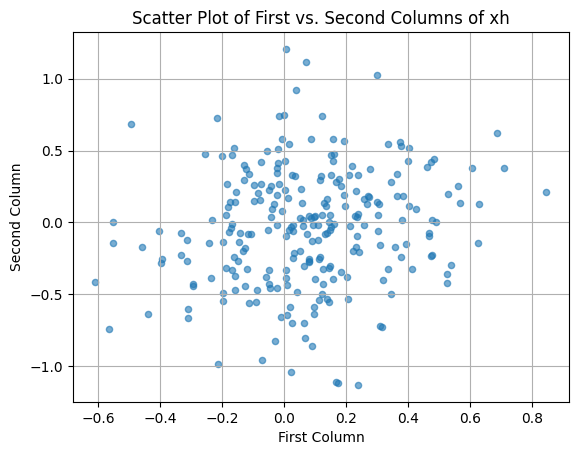

In [82]:
xh,_=Cos_model.sample(nsamples=250,condition_x=torch.tensor([4.,5.0]))
# Convert to numpy
xh_cpu = xh.detach().cpu().numpy()

# Scatter plot of first column vs. second column
plt.scatter(xh_cpu[:, 0], xh_cpu[:, 1], alpha=0.6, s=20)
plt.title("Scatter Plot of First vs. Second Columns of xh")
plt.xlabel("First Column")
plt.ylabel("Second Column")
plt.grid(True)
plt.show()

In [83]:
x_optim = Optimization.optimize_LGD(model_uncond, Cos_model, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD",CM=True)
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 82 | pred_x0_model: tensor([[2.0645, 1.8912]], grad_fn=<AddBackward0>)| pred_x0: tensor([[0.8432, 0.8392]], grad_fn=<AddBackward0>)| mean_loss: 6.866:  17%|█▋        | 17/99 [00:13<01:05,  1.25it/s]   


KeyboardInterrupt: 

In [47]:
x_optim = Optimization.optimize_DPS(model_uncond, Cos_model, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD",CM=True)
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

Step 1 | pred_x0: tensor([[1.0466]], grad_fn=<AddBackward0>)| mean_loss: 0.338: 100%|██████████| 99/99 [00:17<00:00,  5.63it/s] 


tensor([[1.0465]])


100%|██████████| 7/7 [00:00<00:00, 112.07it/s]

tensor(0.8789, dtype=torch.float64)


## D-FLOW

In [172]:
input_dim =mog_means[0].shape[0]
y_dim = mu_list[0].shape[0]-mog_means[0].shape[0]
hidden_dim = 256
depth = 4


In [174]:
y_dim

1

In [175]:

vf_y_cond_x = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=y_dim,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_y_cond_x.train_FM(lr=0.001, batch_size=1024, X=X, nepochs=100)


loss: 7.153823: 100%|██████████| 1/1 [00:09<00:00,  9.47s/it]


In [176]:
first_column_x=X[:,:y_dim]#print()#print()
input_dim = first_column_x.shape[1]
vf_X = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=0,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_X.train_FM(lr=0.001, batch_size=1024, X=first_column_x, nepochs=100)


loss: 8.418447: 100%|██████████| 1/1 [00:07<00:00,  7.10s/it]


### with loss of samples

In [177]:
x_optim,loss= Optimization.optimize_DFLOW(vf_y_cond_x, vf_X, device, mog_means, mog_variances, weights, max_iter=100,FLAG=True,n_sample=500,loss_method="MMD")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim, mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)


x_0: [[-0.7679656]] | x_1: tensor([[-4.6679]], grad_fn=<SelectBackward0>) | loss: 2.4176379299302813
x_0: [[0.09145492]] | x_1: tensor([[1.2878]], grad_fn=<SelectBackward0>) | loss: 2.94908725452007
x_0: [[-0.29709753]] | x_1: tensor([[-3.0768]], grad_fn=<SelectBackward0>) | loss: 1.776358874819401
x_0: [[-0.23531306]] | x_1: tensor([[-2.7250]], grad_fn=<SelectBackward0>) | loss: 1.710153628148905


KeyboardInterrupt: 

### with KL loss

In [178]:
x_optim,loss= Optimization.optimize_DFLOW(vf_y_cond_x, vf_X, device, mog_means, mog_variances, weights, max_iter=100,FLAG=True,n_sample=50,loss_method="KL")
print(x_optim)
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)


x_0: [[-1.2094729]] | x_1: tensor([[-5.5678]], grad_fn=<SelectBackward0>) | loss: 1.6162644624710083


KeyboardInterrupt: 